# Aula 3 — Método dos Elementos Finitos e Introdução ao FEniCSx

Na aula anterior estudamos numericamente o problema de Poisson utilizando o **Método das Diferenças Finitas (MDF)**.

Nesta aula, retomaremos o mesmo problema e construiremos sua solução utilizando o **Método dos Elementos Finitos (MEF)**.

Ao final, veremos como as etapas realizadas manualmente podem ser implementadas de forma sistemática utilizando o **FEniCSx**.

O percurso da aula será

$$
\boxed{
\text{Problema de Poisson}
\longrightarrow
\text{MDF}
\longrightarrow
\text{MEF}
\longrightarrow
\text{FEniCSx}
}
$$

A ideia central é comparar diferentes formas de transformar um **problema contínuo**, descrito por uma equação diferencial parcial, em um **problema algébrico** que pode ser resolvido computacionalmente.

## Preparação do ambiente computacional

Este notebook utiliza **NumPy**, **SymPy**, **Matplotlib** e, posteriormente, **FEniCSx**.

A célula abaixo instala, caso necessário, as bibliotecas Python auxiliares utilizadas durante a aula.

> **Observação:** o FEniCSx e o PETSc fazem parte do ambiente computacional previamente configurado e não são instalados por esta célula.

In [14]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

from mpi4py import MPI
from petsc4py import PETSc

import dolfinx
import ufl

print("NumPy:", np.__version__)
print("SymPy:", sp.__version__)
print("DOLFINx:", dolfinx.__version__)
print("petsc4py:", PETSc.Sys.getVersion())

print("\nAmbiente pronto!")

NumPy: 1.26.4
SymPy: 1.12
DOLFINx: 0.11.0.post0
petsc4py: (3, 19, 6)

Ambiente pronto!


## Preparando o ambiente computacional

Antes de iniciarmos a implementação, vamos carregar as bibliotecas que serão utilizadas ao longo da aula.

- **NumPy (`numpy`)**: operações numéricas com vetores e matrizes;
- **SymPy (`sympy`)**: manipulação simbólica de expressões matemáticas;
- **Matplotlib (`matplotlib.pyplot`)**: construção de gráficos;
- **Matplotlib Tri (`matplotlib.tri`)**: representação e visualização de malhas triangulares;
- **MPI (`mpi4py`)**: infraestrutura de comunicação paralela utilizada pelo FEniCSx;
- **PETSc (`petsc4py`)**: álgebra linear e solução dos sistemas resultantes da discretização;
- **DOLFINx (`dolfinx`)**: implementação do Método dos Elementos Finitos;
- **UFL (`ufl`)**: linguagem utilizada para escrever as formas variacionais.

Também vamos exibir as versões das principais bibliotecas instaladas. Isso permite registrar o ambiente computacional utilizado na aula e facilita a reprodução dos resultados.

## 1. Revisão — Problema de Poisson e Método das Diferenças Finitas

Considere o problema de Poisson

$$
-\Delta u=f
\qquad \text{em } \Omega=(0,1)\times(0,1),
$$

com condição de contorno de Dirichlet homogênea,

$$
u=0
\qquad \text{em } \partial\Omega.
$$

Na aula anterior utilizamos uma **solução manufaturada**

$$
\boxed{
u(x,y)=x(1-x)y(1-y)
}
$$

e determinamos o termo fonte $f$ a partir de

$$
f=-\Delta u.
$$

Em coordenadas cartesianas,

$$
-\left(
\frac{\partial^2u}{\partial x^2}
+
\frac{\partial^2u}{\partial y^2}
\right)
=f.
$$

No Método das Diferenças Finitas, as derivadas segundas foram aproximadas nos pontos da malha por

$$
\frac{\partial^2u}{\partial x^2}
\approx
\frac{
u_{i+1,j}-2u_{i,j}+u_{i-1,j}
}{h^2},
$$

e

$$
\frac{\partial^2u}{\partial y^2}
\approx
\frac{
u_{i,j+1}-2u_{i,j}+u_{i,j-1}
}{h^2}.
$$

Assim, a EDP foi transformada em um sistema de equações algébricas,

$$
\boxed{
A\mathbf{u}=\mathbf{b}
}
$$

cujas incógnitas são os valores aproximados da solução nos pontos interiores da malha.

Portanto, no MDF seguimos essencialmente o caminho

$$
\boxed{
\text{EDP}
\longrightarrow
\text{malha}
\longrightarrow
\text{aproximação das derivadas}
\longrightarrow
\text{sistema linear}
}
$$

Agora faremos algo conceitualmente diferente: em vez de aproximar diretamente as derivadas da EDP, construiremos uma **formulação variacional** do problema.

## 2. Da forma forte à forma fraca

Partimos do problema de Poisson na sua **forma forte**:

$$
-\Delta u=f
\qquad \text{em } \Omega,
$$

com

$$
u=0
\qquad \text{em } \partial\Omega.
$$

Na forma forte, estamos exigindo que a equação diferencial seja satisfeita em cada ponto do domínio.

O Método dos Elementos Finitos seguirá outro caminho.

Introduzimos uma função teste $v$ e multiplicamos a equação por essa função:

$$
-\Delta u\,v=fv.
$$

Integrando sobre todo o domínio,

$$
-\int_\Omega (\Delta u)v\,d\Omega
=
\int_\Omega fv\,d\Omega.
$$

Agora utilizamos a identidade

$$
\nabla\cdot(v\nabla u)
=
\nabla v\cdot\nabla u
+
v\Delta u.
$$

Portanto,

$$
v\Delta u
=
\nabla\cdot(v\nabla u)
-
\nabla v\cdot\nabla u.
$$

Substituindo na integral,

$$
-\int_\Omega
\nabla\cdot(v\nabla u)\,d\Omega
+
\int_\Omega
\nabla u\cdot\nabla v\,d\Omega
=
\int_\Omega fv\,d\Omega.
$$

Pelo **Teorema da Divergência**,

$$
\int_\Omega
\nabla\cdot(v\nabla u)\,d\Omega
=
\int_{\partial\Omega}
v\,\nabla u\cdot\mathbf n\,d\Gamma.
$$

Logo,

$$
\int_\Omega
\nabla u\cdot\nabla v\,d\Omega
-
\int_{\partial\Omega}
v\,\nabla u\cdot\mathbf n\,d\Gamma
=
\int_\Omega fv\,d\Omega.
$$

Como temos uma condição de Dirichlet homogênea,

$$
u=0
\qquad\text{em }\partial\Omega,
$$

escolhemos funções teste que também satisfazem

$$
v=0
\qquad\text{em }\partial\Omega.
$$

Assim, o termo de contorno desaparece e obtemos

$$
\boxed{
\int_\Omega
\nabla u\cdot\nabla v\,d\Omega
=
\int_\Omega
fv\,d\Omega
}
$$

para toda função teste admissível $v$.

Esta é a **forma fraca**, ou **formulação variacional**, do problema de Poisson.

### O que ganhamos com essa transformação?

Na forma forte aparece uma derivada de segunda ordem:

$$
-\Delta u=f.
$$

Na forma fraca aparecem apenas derivadas de primeira ordem:

$$
\nabla u
\qquad\text{e}\qquad
\nabla v.
$$

Portanto,

$$
\boxed{
\text{forma forte: derivadas de segunda ordem}
\quad\longrightarrow\quad
\text{forma fraca: derivadas de primeira ordem}
}
$$

Essa redução na ordem das derivadas é uma das ideias fundamentais que tornam possível utilizar funções aproximadoras simples, como funções **lineares por partes**, no Método dos Elementos Finitos.

A próxima etapa será substituir o espaço infinito de funções admissíveis por um espaço de dimensão finita $V_h$.

## 3. Discretização pelo Método dos Elementos Finitos

A formulação fraca ainda é um problema contínuo:

> encontrar uma função $u$ tal que

$$
\int_\Omega \nabla u\cdot\nabla v\,d\Omega
=
\int_\Omega fv\,d\Omega
$$

para toda função teste admissível $v$.

Ainda estamos, portanto, procurando uma **função** em um espaço de dimensão infinita.

A ideia fundamental do Método dos Elementos Finitos é substituir esse espaço por um espaço de dimensão finita $V_h$.

Para isso, dividimos o domínio $\Omega$ em pequenos subdomínios chamados **elementos**.

No nosso problema bidimensional, utilizaremos elementos triangulares:

$$
\Omega
\approx
\bigcup_{e=1}^{N_e}\Omega_e.
$$

Sobre essa malha, aproximamos a solução por

$$
u_h(x,y)
=
\sum_{j=1}^{N} U_j\,\phi_j(x,y),
$$

onde:

- $\phi_j(x,y)$ são as **funções de forma** ou **funções de base**;
- $U_j$ são os valores nodais desconhecidos;
- $N$ é o número de graus de liberdade.

Da mesma forma, podemos escolher como função teste uma função da base,

$$
v_h=\phi_i.
$$

Substituindo na formulação fraca,

$$
\int_\Omega
\nabla
\left(
\sum_{j=1}^{N}U_j\phi_j
\right)
\cdot
\nabla\phi_i
\,d\Omega
=
\int_\Omega f\phi_i\,d\Omega.
$$

Pela linearidade,

$$
\sum_{j=1}^{N}
U_j
\int_\Omega
\nabla\phi_j\cdot\nabla\phi_i
\,d\Omega
=
\int_\Omega f\phi_i\,d\Omega.
$$

Definindo

$$
K_{ij}
=
\int_\Omega
\nabla\phi_i\cdot\nabla\phi_j\,d\Omega
$$

e

$$
F_i
=
\int_\Omega
f\phi_i\,d\Omega,
$$

obtemos finalmente

$$
\boxed{
K\mathbf U=\mathbf F
}
$$

O problema de encontrar uma função $u(x,y)$ foi transformado em um problema de álgebra linear: encontrar os valores nodais

$$
\mathbf U=
\begin{bmatrix}
U_1 & U_2 & \cdots & U_N
\end{bmatrix}^{T}.
$$

### MDF e MEF: dois caminhos para um sistema linear

Tanto o Método das Diferenças Finitas quanto o Método dos Elementos Finitos transformam o problema contínuo em um sistema de equações algébricas.

No **MDF**, partimos diretamente da forma forte

$$
-\Delta u=f
$$

e aproximamos as derivadas nos pontos da malha:

$$
\boxed{
\text{EDP}
\longrightarrow
\text{aproximação das derivadas}
\longrightarrow
A\mathbf{u}=\mathbf{b}
}
$$

No **MEF**, partimos da forma fraca e aproximamos a própria solução por uma combinação de funções de base:

$$
u_h=\sum_{j=1}^{N}U_j\phi_j.
$$

Assim,

$$
\boxed{
\text{EDP}
\longrightarrow
\text{forma fraca}
\longrightarrow
\text{funções de base}
\longrightarrow
K\mathbf{U}=\mathbf{F}
}
$$

Portanto, os dois métodos chegam a um sistema linear, mas por caminhos diferentes:

$$
\boxed{
\begin{array}{c}
\text{MDF: aproxima as derivadas}\\[4pt]
\text{MEF: aproxima a solução}
\end{array}
}
$$

Vamos agora construir explicitamente o sistema do MEF, começando pelo seu elemento mais simples em duas dimensões: o **triângulo linear**.

## 4. O elemento triangular linear

Considere inicialmente um único elemento triangular com vértices

$$
P_1=(0,0),\qquad
P_2=(1,0),\qquad
P_3=(0,1).
$$

Queremos aproximar a solução $u(x,y)$ no interior desse elemento utilizando os valores da solução nos três vértices,

$$
U_1,\qquad U_2,\qquad U_3.
$$

Para isso, escrevemos

$$
\boxed{
u_h(x,y)
=
U_1\phi_1(x,y)
+
U_2\phi_2(x,y)
+
U_3\phi_3(x,y)
}
$$

onde $\phi_1$, $\phi_2$ e $\phi_3$ são as **funções de forma** do elemento.

Como estamos utilizando um elemento linear, procuramos funções da forma

$$
\phi_i(x,y)=a_i+b_i x+c_i y.
$$

Cada função de forma deve valer $1$ em seu próprio nó e $0$ nos demais:

$$
\phi_i(P_j)=
\begin{cases}
1, & i=j,\\
0, & i\neq j.
\end{cases}
$$

Para o triângulo considerado, essas condições fornecem diretamente

$$
\boxed{
\phi_1(x,y)=1-x-y
}
$$

$$
\boxed{
\phi_2(x,y)=x
}
$$

$$
\boxed{
\phi_3(x,y)=y
}
$$

Observe que

$$
\phi_1+\phi_2+\phi_3=1.
$$

Consequentemente,

$$
u_h(x,y)
=
U_1(1-x-y)+U_2x+U_3y.
$$

A solução aproximada é, portanto, **linear dentro de cada elemento triangular**.

In [15]:
x, y = sp.symbols("x y")

phi1 = 1 - x - y
phi2 = x
phi3 = y

nos = [(0, 0), (1, 0), (0, 1)]

for i, phi in enumerate([phi1, phi2, phi3], start=1):
    valores = [phi.subs({x: xi, y: yi}) for xi, yi in nos]
    print(f"phi_{i} nos nós = {valores}")

print("\nSoma das funções de forma:")
sp.simplify(phi1 + phi2 + phi3)

phi_1 nos nós = [1, 0, 0]
phi_2 nos nós = [0, 1, 0]
phi_3 nos nós = [0, 0, 1]

Soma das funções de forma:


1

### 4.1 Gradientes das funções de forma

A matriz de rigidez do elemento é construída a partir dos gradientes das funções de forma:

$$
K_{ij}^{(e)}
=
\int_{\Omega_e}
\nabla\phi_i\cdot\nabla\phi_j\,d\Omega.
$$

Para o nosso triângulo,

$$
\phi_1=1-x-y,
\qquad
\phi_2=x,
\qquad
\phi_3=y.
$$

Calculando os gradientes,

$$
\nabla\phi_1
=
\begin{bmatrix}
-1\\
-1
\end{bmatrix},
\qquad
\nabla\phi_2
=
\begin{bmatrix}
1\\
0
\end{bmatrix},
\qquad
\nabla\phi_3
=
\begin{bmatrix}
0\\
1
\end{bmatrix}.
$$

Observe uma propriedade importante: como as funções de forma são lineares, seus gradientes são **constantes dentro do elemento**.

Assim, os produtos escalares também são constantes:

$$
\nabla\phi_1\cdot\nabla\phi_1=2,
$$

$$
\nabla\phi_1\cdot\nabla\phi_2=-1,
\qquad
\nabla\phi_1\cdot\nabla\phi_3=-1,
$$

$$
\nabla\phi_2\cdot\nabla\phi_2=1,
\qquad
\nabla\phi_2\cdot\nabla\phi_3=0,
$$

$$
\nabla\phi_3\cdot\nabla\phi_3=1.
$$

### 4.2 Matriz de rigidez do elemento

Como os gradientes são constantes dentro do triângulo,

$$
K_{ij}^{(e)}
=
\left(
\nabla\phi_i\cdot\nabla\phi_j
\right)
\int_{\Omega_e}d\Omega.
$$

O triângulo possui base e altura iguais a $1$. Portanto,

$$
|\Omega_e|=\frac{1}{2}.
$$

Logo,

$$
K_{ij}^{(e)}
=
\frac{1}{2}
\left(
\nabla\phi_i\cdot\nabla\phi_j
\right).
$$

Organizando todos os produtos escalares,

$$
K^{(e)}
=
\frac{1}{2}
\begin{bmatrix}
2 & -1 & -1\\
-1 & 1 & 0\\
-1 & 0 & 1
\end{bmatrix}.
$$

Portanto,

$$
\boxed{
K^{(e)}
=
\begin{bmatrix}
1 & -\frac12 & -\frac12\\[4pt]
-\frac12 & \frac12 & 0\\[4pt]
-\frac12 & 0 & \frac12
\end{bmatrix}
}
$$

Esta é a **matriz de rigidez elementar** associada ao nosso primeiro triângulo.

### 4.3 Verificação simbólica da matriz elementar

Acima calculamos a matriz de rigidez utilizando o fato de que os gradientes das funções de forma são constantes no elemento triangular.

Podemos agora verificar o mesmo resultado calculando diretamente cada entrada pela definição

$$
K_{ij}^{(e)}
=
\int_{\Omega_e}
\nabla\phi_i\cdot\nabla\phi_j
\,d\Omega.
$$

Nosso elemento é o triângulo de vértices

$$
(0,0),\qquad (1,0),\qquad (0,1).
$$

A fronteira inclinada do triângulo é a reta que liga $(1,0)$ a $(0,1)$:

$$
x+y=1,
$$

ou, equivalentemente,

$$
y=1-x.
$$

Para percorrer todo o triângulo, fazemos:

$$
0\leq x\leq1.
$$

Fixado um valor de $x$, a coordenada $y$ varia desde a base do triângulo,

$$
y=0,
$$

até a reta inclinada,

$$
y=1-x.
$$

Portanto, os limites de integração são

$$
\boxed{
0\leq x\leq1,
\qquad
0\leq y\leq1-x
}
$$

e a integral sobre o elemento pode ser escrita como

$$
\boxed{
K_{ij}^{(e)}
=
\int_{0}^{1}
\int_{0}^{1-x}
\nabla\phi_i\cdot\nabla\phi_j
\,dy\,dx
}.
$$

No código abaixo, os dois laços `for` percorrem todas as combinações das três funções de forma:

$$
i=0,1,2,
\qquad
j=0,1,2.
$$

Para cada par $(i,j)$:

1. calculamos o produto escalar
   $$
   \nabla\phi_i\cdot\nabla\phi_j;
   $$

2. integramos esse resultado primeiro em $y$,
   $$
   0\leq y\leq1-x;
   $$

3. em seguida, integramos em $x$,
   $$
   0\leq x\leq1;
   $$

4. armazenamos o resultado na posição correspondente da matriz `K_e`.

Assim, o comando

```python
sp.integrate(
    integrando,
    (y, 0, 1 - x),
    (x, 0, 1)
)

In [16]:
grad_phi = [
    sp.Matrix([sp.diff(phi1, x), sp.diff(phi1, y)]),
    sp.Matrix([sp.diff(phi2, x), sp.diff(phi2, y)]),
    sp.Matrix([sp.diff(phi3, x), sp.diff(phi3, y)])
]

K_e = sp.zeros(3, 3)

for i in range(3):
    for j in range(3):
        integrando = grad_phi[i].dot(grad_phi[j])

        K_e[i, j] = sp.integrate(
            integrando,
            (y, 0, 1 - x),
            (x, 0, 1)
        )

K_e

Matrix([
[   1, -1/2, -1/2],
[-1/2,  1/2,    0],
[-1/2,    0,  1/2]])

### 4.3 Vetor de forças do elemento

Para construir o vetor de forças elementar, precisamos do termo fonte $f(x,y)$.

A solução manufaturada é

$$
u(x,y)=x(1-x)y(1-y).
$$

Como

$$
-\Delta u=f,
$$

temos

$$
f=
-\left(
\frac{\partial^2u}{\partial x^2}
+
\frac{\partial^2u}{\partial y^2}
\right).
$$

Calculando as derivadas,

$$
\frac{\partial^2u}{\partial x^2}
=
-2y(1-y),
$$

e

$$
\frac{\partial^2u}{\partial y^2}
=
-2x(1-x).
$$

Portanto,

$$
\boxed{
f(x,y)
=
2\left[
x(1-x)+y(1-y)
\right].
}
$$

O vetor de forças associado ao elemento é definido por

$$
F_i^{(e)}
=
\int_{\Omega_e}f(x,y)\phi_i(x,y)\,d\Omega.
$$

Assim,

$$
\mathbf F^{(e)}
=
\begin{bmatrix}
\displaystyle\int_{\Omega_e}f\phi_1\,d\Omega\\[8pt]
\displaystyle\int_{\Omega_e}f\phi_2\,d\Omega\\[8pt]
\displaystyle\int_{\Omega_e}f\phi_3\,d\Omega
\end{bmatrix}.
$$

Diferentemente da matriz de rigidez deste elemento, o integrando agora não é constante. Precisamos, portanto, realizar efetivamente as integrais sobre o triângulo.

### Vetor de forças do elemento

Para o problema de Poisson, cada componente do vetor de forças elementar é dado por

$$
F_i^{(e)}
=
\int_{\Omega_e} f\,\phi_i\,d\Omega.
$$

Para o triângulo considerado,

$$
0\leq x\leq1,
\qquad
0\leq y\leq1-x,
$$

de modo que

$$
F_i^{(e)}
=
\int_0^1
\int_0^{1-x}
f(x,y)\,\phi_i(x,y)
\,dy\,dx.
$$

Como temos três funções de forma, obtemos três componentes:

$$
\mathbf F^{(e)}
=
\begin{bmatrix}
F_1^{(e)}\\
F_2^{(e)}\\
F_3^{(e)}
\end{bmatrix}.
$$

In [56]:
x, y = sp.symbols("x y")
f = 2*(x*(1 - x) + y*(1 - y))   
F_e = sp.zeros(3, 1)

for i, phi in enumerate([phi1, phi2, phi3]):
    F_e[i] = sp.integrate(
        f * phi,
        (y, 0, 1 - x),
        (x, 0, 1)
    )

print("Termo fonte:")
display(f)

print("Vetor de forças elementar:")
display(F_e)

Termo fonte:


2*x*(1 - x) + 2*y*(1 - y)

Vetor de forças elementar:


Matrix([
[1/10],
[7/60],
[7/60]])

## O elemento está completo

Para o primeiro triângulo, construímos agora os dois objetos fundamentais do Método dos Elementos Finitos:

$$
K^{(e)}
=
\begin{bmatrix}
1 & -\frac12 & -\frac12\\
-\frac12 & \frac12 & 0\\
-\frac12 & 0 & \frac12
\end{bmatrix}
$$

e

$$
\boxed{
\mathbf{F}^{(e)}
=
\begin{bmatrix}
\frac{1}{10}\\[4pt]
\frac{7}{60}\\[4pt]
\frac{7}{60}
\end{bmatrix}
}.
$$

Cada elemento da malha produzirá sua própria contribuição

$$
K^{(e)}
\qquad\text{e}\qquad
\mathbf F^{(e)}.
$$

O próximo passo é compreender como as contribuições dos diferentes elementos são reunidas para formar o sistema global

$$
\boxed{
K\mathbf U=\mathbf F.
}
$$

Esse processo é chamado de **montagem global** (*assembly*).

## 5. Montagem do sistema global

Voltamos agora ao domínio original,

$$
\Omega=(0,1)\times(0,1).
$$

Como a condição de contorno é

$$
u=0
\qquad\text{em }\partial\Omega,
$$

precisamos de pelo menos um nó no interior do domínio para obter uma incógnita.

Considere os cinco nós

$$
P_1=(0,0),\qquad
P_2=(1,0),\qquad
P_3=(1,1),
$$

$$
P_4=(0,1),\qquad
P_5=\left(\frac12,\frac12\right).
$$

Dividimos o domínio em quatro elementos triangulares:

$$
\Omega_1=(P_1,P_2,P_5),
$$

$$
\Omega_2=(P_2,P_3,P_5),
$$

$$
\Omega_3=(P_3,P_4,P_5),
$$

$$
\Omega_4=(P_4,P_1,P_5).
$$

A malha possui, portanto, quatro elementos e cinco graus de liberdade nodais.

Entretanto, como

$$
U_1=U_2=U_3=U_4=0,
$$

a única incógnita será

$$
\boxed{U_5}.
$$

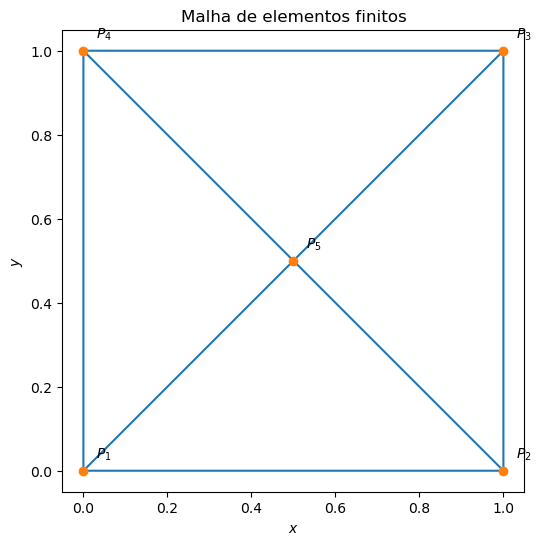

In [18]:
pontos = np.array([
    [0.0, 0.0],   # P1
    [1.0, 0.0],   # P2
    [1.0, 1.0],   # P3
    [0.0, 1.0],   # P4
    [0.5, 0.5]    # P5
])

elementos = np.array([
    [0, 1, 4],
    [1, 2, 4],
    [2, 3, 4],
    [3, 0, 4]
])

triangulacao = mtri.Triangulation(
    pontos[:, 0],
    pontos[:, 1],
    elementos
)

fig, ax = plt.subplots(figsize=(6, 6))

ax.triplot(triangulacao, marker="o")

for i, (x_i, y_i) in enumerate(pontos, start=1):
    ax.text(
        x_i + 0.03,
        y_i + 0.03,
        rf"$P_{i}$"
    )

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_title("Malha de elementos finitos")
ax.set_aspect("equal")
ax.grid(0)

plt.show()

### 5.1 Montagem global

Cada triângulo possui sua própria matriz e seu próprio vetor:

$$
K^{(e)}
\qquad\text{e}\qquad
\mathbf F^{(e)}.
$$

Entretanto, os elementos não são independentes: eles **compartilham nós**.

Por exemplo, o nó $P_5$ pertence aos quatro elementos.

A montagem global consiste em adicionar as contribuições de cada elemento nas posições correspondentes aos seus nós globais:

$$
\boxed{
K=\sum_e K^{(e)}
}
$$

e

$$
\boxed{
\mathbf F=\sum_e\mathbf F^{(e)}.
}
$$

Essa soma deve ser entendida levando em consideração a correspondência entre os **números locais** dos nós de cada elemento e seus **números globais** na malha.

Para nossa malha,

$$
\begin{array}{c|ccc}
\text{elemento} & \text{nó local 1} & \text{nó local 2} & \text{nó local 3}\\
\hline
1 & P_1 & P_2 & P_5\\
2 & P_2 & P_3 & P_5\\
3 & P_3 & P_4 & P_5\\
4 & P_4 & P_1 & P_5
\end{array}
$$

Assim, cada elemento fornece uma pequena contribuição $3\times3$, que é inserida na matriz global $5\times5$.

### 5.2 Cálculo das matrizes elementares

Para cada elemento triangular, precisamos calcular

$$
K_{ij}^{(e)}
=
\int_{\Omega_e}
\nabla\phi_i\cdot\nabla\phi_j\,d\Omega.
$$

Como as funções de forma são lineares, seus gradientes são constantes dentro de cada elemento.

Podemos, portanto, construir uma função que receba as coordenadas dos três nós de um elemento e retorne sua matriz de rigidez $K^{(e)}$.

In [57]:
def matriz_elementar(coords):
    
    # Matriz que determina as funções de forma
    C = np.column_stack((
        np.ones(3),
        coords[:, 0],
        coords[:, 1]
    ))
    
    # Área do triângulo
    area = abs(np.linalg.det(C)) / 2
    
    # Cada coluna contém os coeficientes
    # [a_i, b_i, c_i] da função phi_i
    coef = np.linalg.inv(C)
    
    # Gradientes das funções de forma
    grad_phi = coef[1:, :]
    
    # Matriz de rigidez elementar
    K_e = area * grad_phi.T @ grad_phi
    
    return K_e, area

In [58]:
coords_teste = np.array([
    [0.0, 0.0],
    [1.0, 0.0],
    [0.0, 1.0]
])

K_teste, area_teste = matriz_elementar(coords_teste)

print("Área =", area_teste)
print("\nMatriz elementar:")
print(K_teste)

Área = 0.5

Matriz elementar:
[[ 1.  -0.5 -0.5]
 [-0.5  0.5  0. ]
 [-0.5  0.   0.5]]


## 5.3 Vetor de forças elementar

Também precisamos calcular, para cada elemento,

$$
F_i^{(e)}
=
\int_{\Omega_e} f(x,y)\phi_i(x,y)\,d\Omega.
$$

No primeiro triângulo, conseguimos realizar essa integração diretamente porque conhecíamos sua geometria e seus limites de integração.

Agora queremos automatizar o cálculo para **qualquer triângulo da malha**.

Para isso, utilizaremos um **triângulo de referência**, com coordenadas $(\xi,\eta)$ e vértices

$$
(0,0),\qquad (1,0),\qquad (0,1).
$$

Nesse triângulo,

$$
0\leq \xi\leq 1,
\qquad
0\leq \eta\leq 1-\xi,
$$

e as funções de forma são

$$
N_1=1-\xi-\eta,
\qquad
N_2=\xi,
\qquad
N_3=\eta.
$$

Cada ponto do triângulo de referência é levado ao elemento físico por

$$
x(\xi,\eta)
=
x_1N_1+x_2N_2+x_3N_3,
$$

$$
y(\xi,\eta)
=
y_1N_1+y_2N_2+y_3N_3.
$$

A mudança de coordenadas introduz o determinante da matriz Jacobiana $J$:

$$
d\Omega
=
|\det J|\,d\xi\,d\eta.
$$

Assim, o vetor de forças elementar pode ser calculado por

$$
\boxed{
F_i^{(e)}
=
\int_0^1
\int_0^{1-\xi}
f\bigl(x(\xi,\eta),y(\xi,\eta)\bigr)
N_i(\xi,\eta)
|\det J|
\,d\eta\,d\xi
}
$$

Dessa forma, utilizamos sempre os mesmos limites de integração no triângulo de referência, enquanto a transformação $(\xi,\eta)\mapsto(x,y)$ adapta o cálculo à posição e à geometria de cada elemento da malha.

A seguir, vamos implementar esse procedimento simbolicamente com o SymPy.

In [24]:
def fonte(x, y):
    return 2 * (x * (1 - x) + y * (1 - y))


def vetor_elementar(coords):

    # Coordenadas dos vértices do elemento físico
    x1, y1 = coords[0]
    x2, y2 = coords[1]
    x3, y3 = coords[2]

    # Coordenadas simbólicas no triângulo de referência
    xi, eta = sp.symbols("xi eta", real=True)

    # Funções de forma no triângulo de referência
    N1 = 1 - xi - eta
    N2 = xi
    N3 = eta

    N = [N1, N2, N3]

    # Transformação do triângulo de referência
    # para o triângulo físico
    x_phys = x1 * N1 + x2 * N2 + x3 * N3
    y_phys = y1 * N1 + y2 * N2 + y3 * N3

    # Matriz Jacobiana da transformação
    J = sp.Matrix([
        [sp.diff(x_phys, xi),  sp.diff(x_phys, eta)],
        [sp.diff(y_phys, xi),  sp.diff(y_phys, eta)]
    ])

    detJ = sp.Abs(J.det())

    # Função fonte no elemento físico
    f_phys = fonte(x_phys, y_phys)

    # Vetor de forças elementar
    F_e = np.zeros(3)

    for i in range(3):

        integrando = f_phys * N[i] * detJ

        integral = sp.integrate(
            integrando,
            (eta, 0, 1 - xi),
            (xi, 0, 1)
        )

        F_e[i] = float(integral)

    return F_e

O cálculo acima segue diretamente a expressão

$$
F_i^{(e)}
=
\int_0^1
\int_0^{1-\xi}
f\bigl(x(\xi,\eta),y(\xi,\eta)\bigr)
N_i(\xi,\eta)
|\det J|
\,d\eta\,d\xi.
$$

Observe a sequência implementada no código:

1. recebemos as coordenadas dos três vértices do elemento;
2. definimos as funções de forma $N_1$, $N_2$ e $N_3$ no triângulo de referência;
3. construímos a transformação $(\xi,\eta)\mapsto(x,y)$;
4. calculamos o Jacobiano da transformação;
5. escrevemos a função fonte nas coordenadas do elemento físico;
6. integramos $fN_i|\det J|$ sobre o triângulo de referência.

Diferentemente da aproximação pelo centróide, estamos agora calculando diretamente a integral que define cada componente do vetor de forças elementar.

### Como a matriz elementar é inserida na matriz global

Antes de realizar a montagem, é importante distinguir entre **numeração local** e **numeração global** dos nós.

Considere o elemento 1, formado pelos nós globais

$$
[1,2,5].
$$

Sua matriz de rigidez elementar é

$$
K^{(1)}=
\begin{bmatrix}
0.5 & 0 & -0.5\\
0 & 0.5 & -0.5\\
-0.5 & -0.5 & 1
\end{bmatrix}.
$$

As linhas e as colunas dessa matriz correspondem aos **nós locais do elemento**:

$$
\begin{array}{c|ccc}
\text{nó local} & 1 & 2 & 3\\ \hline
\text{nó global} & 1 & 2 & 5
\end{array}
$$

Portanto, podemos interpretar a matriz elementar colocando os números
dos nós globais nas linhas e nas colunas:

$$
\begin{array}{c|ccc}
 & 1 & 2 & 5\\ \hline
1 & 0.5 & 0 & -0.5\\
2 & 0 & 0.5 & -0.5\\
5 & -0.5 & -0.5 & 1
\end{array}
$$

Por exemplo,

$$
(K_e)_{11}=0.5
\quad\longrightarrow\quad
K_{11},
$$

enquanto

$$
(K_e)_{13}=-0.5
\quad\longrightarrow\quad
K_{15},
$$

pois o nó local 3 corresponde ao nó global 5.

Da mesma forma,

$$
(K_e)_{23}=-0.5
\quad\longrightarrow\quad
K_{25},
$$

e

$$
(K_e)_{33}=1
\quad\longrightarrow\quad
K_{55}.
$$

Assim, a matriz do elemento 1 ocupa somente as linhas e colunas globais

$$
[1,2,5]\times[1,2,5].
$$

Sua contribuição para a matriz global é, portanto,

$$
K_{\mathrm{global}}^{(1)}
=
\begin{bmatrix}
0.5 & 0 & 0 & 0 & -0.5\\
0 & 0.5 & 0 & 0 & -0.5\\
0 & 0 & 0 & 0 & 0\\
0 & 0 & 0 & 0 & 0\\
-0.5 & -0.5 & 0 & 0 & 1
\end{bmatrix}.
$$

Os nós globais 3 e 4 não pertencem a esse elemento e, por isso, o
elemento 1 não produz contribuições nas linhas e colunas associadas
exclusivamente a esses nós.

O mesmo procedimento é realizado para todos os elementos:

$$
\begin{aligned}
e=1 &: [1,2,5],\\
e=2 &: [2,3,5],\\
e=3 &: [3,4,5],\\
e=4 &: [4,1,5].
\end{aligned}
$$

Quando dois ou mais elementos contribuem para a mesma posição da
matriz global, essas contribuições são **somadas**.

Por exemplo, o nó global 1 pertence aos elementos 1 e 4. Portanto,

$$
K_{11}=0.5+0.5=1.
$$

A montagem global consiste justamente em repetir esse processo
automaticamente para todos os elementos da malha.

### 5.4 Montagem do sistema global

Agora percorremos todos os elementos da malha.

Para cada elemento:

1. identificamos seus três nós;
2. calculamos $K^{(e)}$ e $\mathbf F^{(e)}$;
3. adicionamos essas contribuições nas posições correspondentes da matriz e do vetor globais.

Inicialmente,

$$
K=\mathbf 0_{5\times5},
\qquad
\mathbf F=\mathbf 0_{5}.
$$

Para um elemento cujos nós globais são $(i,j,k)$, sua matriz $3\times3$ é adicionada às linhas e colunas $(i,j,k)$ da matriz global.

Esse processo é denominado **montagem** (*assembly*).

In [29]:
n_nos = len(pontos)

K = np.zeros((n_nos, n_nos))
F = np.zeros(n_nos)

for e, elemento in enumerate(elementos):
    
    # Coordenadas dos nós do elemento
    coords = pontos[elemento]
    
    # Matrizes elementares
    K_e, area = matriz_elementar(coords)
    F_e = vetor_elementar(coords)
    
    print(f"Elemento {e + 1}: nós {elemento + 1}")
    print("K_e =")
    print(np.round(K_e, 4))
    print("F_e =", np.round(F_e, 4))
    print()
    
    # Montagem global
    for a in range(3):
        A = elemento[a]
        
        F[A] += F_e[a]
        
        for b in range(3):
            B = elemento[b]
            K[A, B] += K_e[a, b]

Elemento 1: nós [1 2 5]
K_e =
[[ 0.5  0.  -0.5]
 [ 0.   0.5 -0.5]
 [-0.5 -0.5  1. ]]
F_e = [0.05   0.05   0.0667]

Elemento 2: nós [2 3 5]
K_e =
[[ 0.5  0.  -0.5]
 [ 0.   0.5 -0.5]
 [-0.5 -0.5  1. ]]
F_e = [0.05   0.05   0.0667]

Elemento 3: nós [3 4 5]
K_e =
[[ 0.5  0.  -0.5]
 [ 0.   0.5 -0.5]
 [-0.5 -0.5  1. ]]
F_e = [0.05   0.05   0.0667]

Elemento 4: nós [4 1 5]
K_e =
[[ 0.5  0.  -0.5]
 [ 0.   0.5 -0.5]
 [-0.5 -0.5  1. ]]
F_e = [0.05   0.05   0.0667]



In [28]:
print("Matriz global K:")
print(np.round(K, 4))

print("\nVetor global F:")
print(np.round(F, 4))

Matriz global K:
[[ 1.  0.  0.  0. -1.]
 [ 0.  1.  0.  0. -1.]
 [ 0.  0.  1.  0. -1.]
 [ 0.  0.  0.  1. -1.]
 [-1. -1. -1. -1.  4.]]

Vetor global F:
[0.1    0.1    0.1    0.1    0.2667]


### 5.5 Condições de contorno

Os nós $P_1$, $P_2$, $P_3$ e $P_4$ pertencem ao contorno.

Como

$$
u=0
\qquad\text{em }\partial\Omega,
$$

temos

$$
U_1=U_2=U_3=U_4=0.
$$

Portanto, resta apenas uma incógnita:

$$
U_5.
$$

A quinta equação do sistema global é

$$
K_{51}U_1+
K_{52}U_2+
K_{53}U_3+
K_{54}U_4+
K_{55}U_5
=
F_5.
$$

Como os quatro primeiros valores são nulos,

$$
\boxed{
K_{55}U_5=F_5.
}
$$

In [30]:
K55 = K[4, 4]
F5 = F[4]

U5 = F5 / K55

u_exata_centro = 0.5 * (1 - 0.5) * 0.5 * (1 - 0.5)

print(f"K55 = {K55:.6f}")
print(f"F5  = {F5:.6f}")

print(f"\nMEF:          U5 = {U5:.6f}")
print(f"Solução exata:   = {u_exata_centro:.6f}")

print(f"Erro absoluto:   = {abs(U5 - u_exata_centro):.6e}")

K55 = 4.000000
F5  = 0.266667

MEF:          U5 = 0.066667
Solução exata:   = 0.062500
Erro absoluto:   = 4.166667e-03


## 6. Do Método dos Elementos Finitos ao FEniCSx

Até aqui implementamos explicitamente as principais etapas do Método dos Elementos Finitos:

$$
\boxed{
\text{malha}
\rightarrow
\text{funções de forma}
\rightarrow
K^{(e)},F^{(e)}
\rightarrow
\text{montagem}
\rightarrow
K\mathbf U=\mathbf F
}
$$

Esse procedimento é perfeitamente viável para uma malha pequena.

Entretanto, ao refinarmos a malha, o número de elementos e de graus de liberdade cresce rapidamente.

Em problemas reais, precisamos automatizar:

- a geração e o gerenciamento da malha;
- a construção do espaço de elementos finitos;
- o cálculo das matrizes e vetores elementares;
- a montagem do sistema global;
- a aplicação das condições de contorno;
- a solução do sistema linear.

O **FEniCSx** é uma plataforma para a solução de equações diferenciais parciais pelo Método dos Elementos Finitos.

Uma de suas principais características é permitir que a **formulação variacional seja escrita de forma muito próxima de sua expressão matemática**.

Para o nosso problema,

$$
-\Delta u=f,
$$

a forma fraca é

$$
\int_\Omega
\nabla u\cdot\nabla v\,d\Omega
=
\int_\Omega
fv\,d\Omega.
$$

No FEniCSx, essa formulação aparecerá praticamente da mesma forma no código.

In [31]:
from dolfinx import mesh, fem
from dolfinx.fem.petsc import LinearProblem

N = 20 # Número de subdivisões do domínio em cada direção (x e y)

domain = mesh.create_unit_square(
    MPI.COMM_WORLD,
    N,
    N
)

V = fem.functionspace(
    domain,
    ("Lagrange", 1)
)

num_celulas = domain.topology.index_map(
    domain.topology.dim
).size_global

num_dofs = V.dofmap.index_map.size_global

print(f"N = {N}")
print(f"Número de células = {num_celulas}")
print(f"Graus de liberdade = {num_dofs}")

N = 20
Número de células = 800
Graus de liberdade = 441


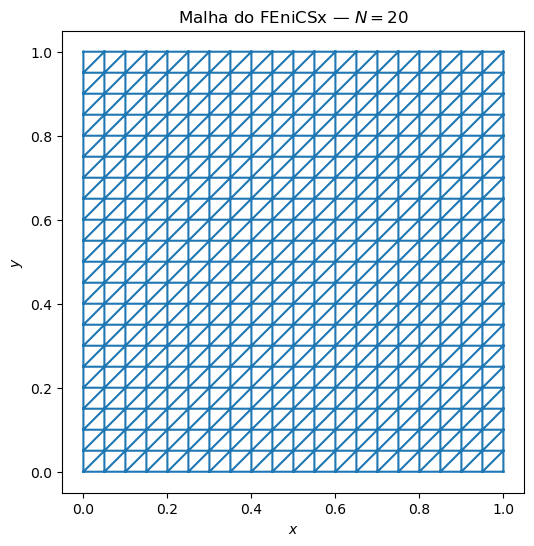

In [32]:
domain.topology.create_connectivity(2, 0)

x_mesh = domain.geometry.x[:, 0]
y_mesh = domain.geometry.x[:, 1]

connectivity = domain.topology.connectivity(2, 0)

triangles = connectivity.array.reshape(-1, 3)

triangulation = mtri.Triangulation(
    x_mesh,
    y_mesh,
    triangles
)

fig, ax = plt.subplots(figsize=(6, 6))

ax.triplot(triangulation)

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_title(fr"Malha do FEniCSx — $N={N}$")
ax.set_aspect("equal")

plt.show()

## 7. A formulação variacional no FEniCSx

Já construímos anteriormente a formulação variacional do problema de Poisson:

$$
\int_\Omega
\nabla u\cdot\nabla v\,d\Omega
=
\int_\Omega
fv\,d\Omega.
$$

Podemos escrevê-la na forma

$$
a(u,v)=L(v),
$$

onde

$$
a(u,v)
=
\int_\Omega
\nabla u\cdot\nabla v\,d\Omega
$$

é uma **forma bilinear**, enquanto

$$
L(v)
=
\int_\Omega
fv\,d\Omega
$$

é uma **forma linear**.

> No FEniCSx, não precisamos construir explicitamente as matrizes elementares nem realizar manualmente a montagem global.

Fornecemos:

- a malha;
- o espaço de elementos finitos;
- a forma bilinear $a(u,v)$;
- a forma linear $L(v)$;
- as condições de contorno.

A partir dessas informações, o FEniCSx realiza a discretização e a montagem do sistema

$$
K\mathbf U=\mathbf F.
$$

In [36]:
u = ufl.TrialFunction(V)
v = ufl.TestFunction(V)

x = ufl.SpatialCoordinate(domain)

f = 2 * (
    x[0] * (1 - x[0])
    +
    x[1] * (1 - x[1])
)

a = ufl.inner(
    ufl.grad(u),
    ufl.grad(v)
) * ufl.dx

L = f * v * ufl.dx

### 7.1 Condição de contorno de Dirichlet

Nosso problema possui a condição

$$
u=0
\qquad\text{em }\partial\Omega.
$$

Precisamos, portanto, identificar os graus de liberdade do espaço de elementos finitos que pertencem ao contorno do domínio e impor neles o valor zero.

No problema que resolvemos manualmente, fizemos exatamente isso ao estabelecer

$$
U_1=U_2=U_3=U_4=0.
$$

No FEniCSx, o procedimento é o mesmo conceitualmente, mas agora a identificação dos nós do contorno é realizada automaticamente a partir da malha.

In [34]:
# Localiza as faces que pertencem ao contorno
facets = mesh.locate_entities_boundary(
    domain,
    dim=domain.topology.dim - 1,
    marker=lambda x: np.full(x.shape[1], True)
)

# Localiza os graus de liberdade associados ao contorno
dofs = fem.locate_dofs_topological(
    V,
    entity_dim=domain.topology.dim - 1,
    entities=facets
)

# Impõe u = 0 nesses graus de liberdade
bc = fem.dirichletbc(
    PETSc.ScalarType(0),
    dofs,
    V
)

print("Graus de liberdade no contorno:", len(dofs))

Graus de liberdade no contorno: 80


### 7.2 Montagem e solução do sistema

Já fornecemos ao FEniCSx todos os ingredientes do problema:

$$
\boxed{
\text{malha}
+
\text{espaço }V
+
a(u,v)
+
L(v)
+
\text{condição de contorno}
}
$$

A partir dessas informações, o FEniCSx pode construir automaticamente o sistema de elementos finitos

$$
K\mathbf U=\mathbf F.
$$

As operações que realizamos anteriormente de forma explícita,

$$
K^{(e)},\qquad
\mathbf F^{(e)},\qquad
\text{montagem global},
$$

agora são realizadas internamente pelo FEniCSx.

In [37]:
problem = LinearProblem(
    a,
    L,
    bcs=[bc],
    petsc_options_prefix="poisson_",
    petsc_options={
        "ksp_type": "preonly",
        "pc_type": "lu"
    }
)

uh = problem.solve()

print("Problema resolvido.")

Problema resolvido.


### 7.3 Visualização da solução aproximada

A solução calculada pelo FEniCSx é uma função de elementos finitos

$$
u_h(x,y)=\sum_j U_j\phi_j(x,y).
$$

Os coeficientes $U_j$ são os valores associados aos graus de liberdade do problema.

Vamos visualizar a função $u_h$ sobre o domínio.

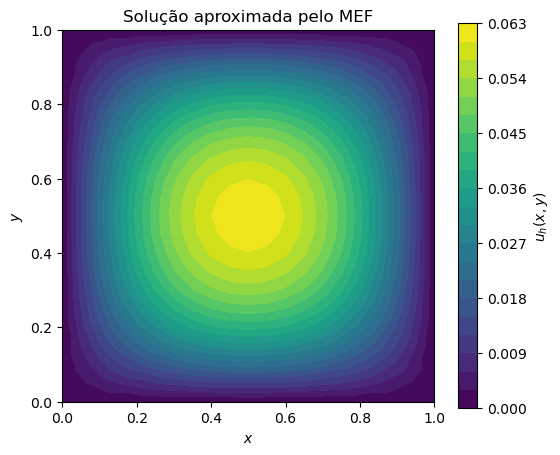

In [38]:
# Coordenadas dos graus de liberdade
coords = V.tabulate_dof_coordinates()

# Valores da solução nos graus de liberdade
u_values = uh.x.array.real

fig, ax = plt.subplots(figsize=(6, 5))

contour = ax.tricontourf(
    coords[:, 0],
    coords[:, 1],
    u_values,
    levels=20
)

fig.colorbar(contour, ax=ax, label=r"$u_h(x,y)$")

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_title("Solução aproximada pelo MEF")
ax.set_aspect("equal")

plt.show()

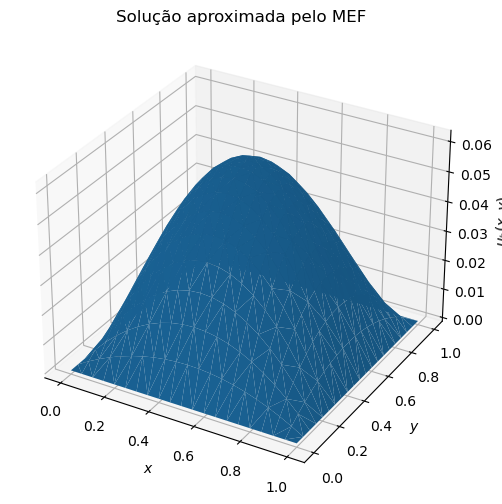

In [39]:
# Coordenadas dos graus de liberdade
coords = V.tabulate_dof_coordinates()

x_dof = coords[:, 0]
y_dof = coords[:, 1]
z_dof = uh.x.array.real

# Triangulação dos pontos
tri = mtri.Triangulation(x_dof, y_dof)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot_trisurf(
    tri,
    z_dof,
    linewidth=0.2,
    antialiased=True
)

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_zlabel(r"$u_h(x,y)$")

ax.set_title("Solução aproximada pelo MEF")

plt.show()

## 8. Refinamento da malha e convergência

O Método dos Elementos Finitos fornece uma solução aproximada $u_h$.

Ao refinar a malha, diminuímos o tamanho característico dos elementos:

$$
h \approx \frac{1}{N}.
$$

Esperamos que

$$
u_h \longrightarrow u
\qquad\text{quando}\qquad
h\longrightarrow 0.
$$

Vamos observar numericamente esse comportamento utilizando

$$
N=2,\;4,\;8,\;16.
$$

In [40]:
def resolver_poisson(N):
    # Malha e espaço de elementos finitos
    domain = mesh.create_unit_square(
        MPI.COMM_WORLD, N, N
    )

    V = fem.functionspace(
        domain,
        ("Lagrange", 1)
    )

    # Funções tentativa e teste
    u = ufl.TrialFunction(V)
    v = ufl.TestFunction(V)

    # Termo fonte
    x = ufl.SpatialCoordinate(domain)

    f = 2 * (
        x[0] * (1 - x[0])
        +
        x[1] * (1 - x[1])
    )

    # Formulação variacional
    a = ufl.inner(
        ufl.grad(u),
        ufl.grad(v)
    ) * ufl.dx

    L = f * v * ufl.dx

    # Condição de contorno u = 0
    fdim = domain.topology.dim - 1

    facets = mesh.locate_entities_boundary(
        domain,
        fdim,
        lambda x: np.full(x.shape[1], True, dtype=bool)
    )

    dofs = fem.locate_dofs_topological(
        V,
        fdim,
        facets
    )

    bc = fem.dirichletbc(
        PETSc.ScalarType(0),
        dofs,
        V
    )

    # Solução
    problem = LinearProblem(
        a,
        L,
        bcs=[bc],
        petsc_options_prefix=f"poisson_{N}_",
        petsc_options={
            "ksp_type": "preonly",
            "pc_type": "lu"
        }
    )

    uh = problem.solve()

    return domain, V, uh

In [46]:
Ns = [2, 4, 8, 16, 20]

solucoes = {}

for N in Ns:
    domain_N, V_N, uh_N = resolver_poisson(N)

    # Guarda a malha, o espaço e a solução para cada N
    solucoes[N] = (domain_N, V_N, uh_N)

    num_elementos = domain_N.topology.index_map(
        domain_N.topology.dim
    ).size_global

    num_dofs = V_N.dofmap.index_map.size_global

    print(
        f"N = {N:2d} | "
        f"h = {1/N:.4f} | "
        f"elementos = {num_elementos:4d} | "
        f"graus de liberdade = {num_dofs:4d}"
    )

N =  2 | h = 0.5000 | elementos =    8 | graus de liberdade =    9
N =  4 | h = 0.2500 | elementos =   32 | graus de liberdade =   25
N =  8 | h = 0.1250 | elementos =  128 | graus de liberdade =   81
N = 16 | h = 0.0625 | elementos =  512 | graus de liberdade =  289
N = 20 | h = 0.0500 | elementos =  800 | graus de liberdade =  441


### Comparação das soluções ao longo de $y=0.5$

Para visualizar a convergência das soluções numéricas, vamos considerar
uma seção horizontal do domínio, fixando

$$
y=0.5.
$$

A solução analítica é

$$
u(x,y)=x(1-x)y(1-y),
$$

portanto, nessa seção,

$$
u(x,0.5)=\frac14 x(1-x).
$$

Como os valores utilizados são $N=2,4,8,16$, a linha $y=0.5$
passa pelos nós de todas as malhas.

Vamos comparar os valores da solução MEF nesses nós com a solução
analítica.

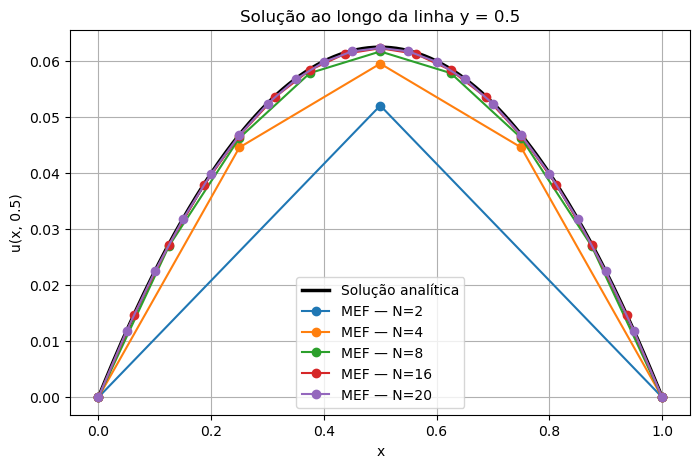

In [47]:
# Pontos para representar a solução analítica
x_exato = np.linspace(0, 1, 300)
u_exato = 0.25 * x_exato * (1 - x_exato)

plt.figure(figsize=(8, 5))

# Solução analítica
plt.plot(
    x_exato,
    u_exato,
    "k-",
    linewidth=2.5,
    label="Solução analítica"
)

# Soluções pelo MEF
for N in Ns:

    domain_N, V_N, uh_N = solucoes[N]

    # Coordenadas dos graus de liberdade
    coords = V_N.tabulate_dof_coordinates()

    # Seleciona os graus de liberdade sobre y = 0.5
    mask = np.isclose(coords[:, 1], 0.5)

    x_num = coords[mask, 0]
    u_num = uh_N.x.array[mask]

    # Ordena os pontos segundo x
    ordem = np.argsort(x_num)

    x_num = x_num[ordem]
    u_num = u_num[ordem]

    plt.plot(
        x_num,
        u_num,
        "o-",
        label=f"MEF — N={N}"
    )

plt.xlabel("x")
plt.ylabel("u(x, 0.5)")
plt.title("Solução ao longo da linha y = 0.5")
plt.grid(True)
plt.legend()
plt.show()

### 8.1 Medindo o erro

Como conhecemos a solução exata,

$$
u(x,y)=x(1-x)y(1-y),
$$

podemos medir a diferença entre a solução exata $u$ e a solução aproximada $u_h$.

Utilizaremos o erro

$$
\|u-u_h\|_{L^2(\Omega)}
=
\left(
\int_\Omega (u-u_h)^2\,d\Omega
\right)^{1/2}.
$$

Neste momento, nosso objetivo é apenas observar experimentalmente que o erro diminui quando a malha é refinada.

In [48]:
def erro_L2(domain, uh):
    x = ufl.SpatialCoordinate(domain)

    u_exata = (
        x[0] * (1 - x[0])
        * x[1] * (1 - x[1])
    )

    erro = fem.form(
        (uh - u_exata)**2 * ufl.dx
    )

    erro_local = fem.assemble_scalar(erro)

    erro_global = domain.comm.allreduce(
        erro_local,
        op=MPI.SUM
    )

    return np.sqrt(erro_global)

In [53]:
Ns = [2, 4, 8, 16, 20]

resultados = []

for N in Ns:
    domain_N, V_N, uh_N = resolver_poisson(N)

    num_elementos = domain_N.topology.index_map(
        domain_N.topology.dim
    ).size_global

    num_dofs = V_N.dofmap.index_map.size_global

    erro = erro_L2(domain_N, uh_N)

    resultados.append([
        N,
        1 / N,
        num_elementos,
        num_dofs,
        erro
    ])

print(
    f"{'N':>4} {'h':>10} {'Elementos':>12} "
    f"{'DOFs':>8} {'Erro L2':>14}"
)

for N, h, ne, nd, erro in resultados:
    print(
        f"{N:4d} {h:10.5f} {ne:12d} "
        f"{nd:8d} {erro:14.6e}"
    )

   N          h    Elementos     DOFs        Erro L2
   2    0.50000            8        9   1.763157e-02
   4    0.25000           32       25   5.449757e-03
   8    0.12500          128       81   1.441427e-03
  16    0.06250          512      289   3.655702e-04
  20    0.05000          800      441   2.343705e-04


## 9. Para refletir

Nesta aula partimos do problema de Poisson, construímos o Método dos Elementos Finitos e vimos como o FEniCSx automatiza as etapas de discretização, montagem e solução.

Observamos também que, à medida que refinamos a malha,

$$
h\longrightarrow 0,
$$

a solução aproximada $u_h$ se aproxima da solução exata $u$.

### Questão

Até agora utilizamos

$$
N=2,\;4,\;8,\;16.
$$

O que aconteceria se utilizássemos, por exemplo,

$$
N=200?
$$

Antes de executar o código, reflita:

1. Quantos elementos triangulares seriam gerados?

2. Quantos graus de liberdade teríamos utilizando elementos $P_1$?

3. A solução seria visualmente muito diferente daquela obtida com $N=16$?

4. O erro continuaria diminuindo?

5. Qual seria o custo computacional desse refinamento?

6. Faz sentido continuar refinando indefinidamente uma malha?

---

### Ideia para levar desta aula

O refinamento da malha produz espaços de aproximação cada vez mais ricos e pode melhorar a solução numérica.

Entretanto,  **maior precisão também significa maior custo computacional**.

Assim, um dos problemas fundamentais da computação científica é encontrar um equilíbrio entre

$$
\boxed{\text{precisão}}
\qquad\text{e}\qquad
\boxed{\text{custo computacional}}.
$$

Na próxima etapa, veremos como essas mesmas ideias de **campo, fluxo, conservação e formulação variacional** aparecem naturalmente nos problemas da Mecânica dos Fluidos.